**Aim:** Identify sun groups of neuronal cells

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [37]:
import scez

scanpy==1.9.1 anndata==0.8.0 umap==0.5.3 numpy==1.22.4 scipy==1.9.0 pandas==1.4.3 scikit-learn==1.1.2 statsmodels==0.13.2 python-igraph==0.9.11 pynndescent==0.5.7


In [5]:
from utils import *

In [6]:
from upsetplot import from_contents, UpSet

In [7]:
def add_marker_feature(adata,marker,marker_name,clusters_name,thr = 0,figsize=(10,4)):

    df = pd.concat([
        adata.obs.groupby([marker_name,clusters_name]).size()[f'{marker}+'],
        adata.obs.groupby([marker_name,clusters_name]).size()[f'{marker}-']
    ],axis=1).rename(columns={0:f'{marker}+',1:f'{marker}-'})
    
    # Make some labels.
    labels = df[f'{marker}+'] / df.sum(axis=1) * 100
    labels = labels.round(decimals=1)
    labels.sort_values(ascending=False,inplace=True)
    df = df.loc[labels.index,]
    
    ax = df.plot.bar(stacked=True,rot=0,figsize=figsize)

    rects = ax.patches

    for rect, label in zip(rects, labels):
        height = rect.get_height()
        ax.text(
            rect.get_x() + rect.get_width() / 2, height + 5, str(label) + "%", 
            ha="center", va="bottom", fontsize=8
        )

    ax.set_yscale('log')
    ax.set_ylabel('# of cells')
    return ax


## marker genes for neuronal/non-neuronal cells

In [76]:
cell_types = {
    "non-neuronal cells":[
        "Endothelial","Oligodentrocyte",
        "OPCs", # oligodendrocyte progenitor cells 
        "Microglia","astrocytes",
        "neuroblast"
        "interneuron",
    ],

    "neuron":[
        "neuron main markers",
        "GABAergic",
        "glutamatergic",
        "D1 MSN",
        "D2 MSN (Ppp1r1b+ medial spiny neuron)",
        "D1H",
        "ICj"
    ]
}

In [195]:
marker_genes = {
    # "OPCs":['Pdgfra','Olig2'], # oligodendrocyte progenitor cells
    # "interneuron":[
    #     # "Resp18",
    #     # 'Lhx6',
    #     'Zic1'
    # ],
    "Endothelial": ["Cldn5","Ptprb"],
    "Oligodentrocyte":["Mog",'Opalin'], # "Olig1",
    "Microglia":['C1qb','C1qa'], #"Cx3cr1",
    "astrocytes":['Slc1a3','Gja1'], #"Aqp4",
    # "neuroblast":["Top2a"],
    # "neuron main markers":[
    #     # 'Snap25',
    #     'Zic2',#"Gria2", "Penk",'Dck','Nrxn1',"Nfasc","Kctd13",
    #     "Sox11" #"Aplp1","Syt11","Slc2a1","Slc1a2","Slc4a4","Slc6a6","Qpct"
    #                       ],
    "GABAergic":["Gad1"],
    "glutamatergic":[
        "Grin3a",
        "Lrrtm2",
        "Slc1a1",
        "Slc1a2",
        "Gria1",
        # "Gria2",
        # "Grin1",
        # "Slc6a13",
        # "Slc7a11",
        # "Slc17a7",
        # "Slc17a6",
    ],
    "D1 MSN":['Tac1',"Pdyn"], # ,"Drd1a"
    # "D2 MSN":[ # (Ppp1r1b+ medial spiny neuron)
    #     "Penk",
    #     # "Drd2",
    #     "Adora2a"
    # ],
    # "D1H":[
        # "Nxph4",
    #     # "Tac2"
    # ],
    # "ICj":[
    #     # "Crtac1",
    #     "Rreb1"],
    # "patch marker":["Sema5b"],
    # "ventral striatum marker":["Crym"],
    # "medial Shell":[
    #     "Stard5",
    #     "Stra6"]
}

In [196]:
neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type in cell_types['neuron']
}

not_neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type not in cell_types['neuron']
}

## Load data 

In [ ]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron = sc.read_h5ad(results_file)

In [347]:
adata_neuron.layers['scaled'] = sc.pp.scale(adata_neuron, copy=True).X

In [348]:
adata_neuron

AnnData object with n_obs × n_vars = 12663 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label', 'leiden_neuron'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_scVI_colors', 'leiden_neuron_colors', 'group_colors', 'rank_genes_groups', 'dendrogram_leiden_neuron'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scvi_normalized', 'scaled'
    obsp: 'distances', 'connectivities'

In [398]:
# new_markers = {
#     "Synaptic cell adhesion/transmission":[
#         "Nrxn1", "Nrxn2", "Nrxn3", "Lrrtm2", "Nlgn3","Nxph1", "Ncam1",'Ncam2', 'Homer2', 'Syt11',
#         'Gria3', 'Gria4', 'Grin2c', 'Camk2d'
#     ],
#     "Cell type markers": [
#         "Gad1", "Gad2", "Pcp4l1", "Sox11",
#     ],
#     "Solute carriers": [
#         "Slc6a6", "Slc38a11", "Slc6a11",
#     ],
#     "Neuromodulator receptor": [
#         "Drd1", "Drd2", "Penk", "Tac1", "Htr2c", "Adora1", 
#         "Npy1r", "Opcml", "Ntsr2", "Ntrk2",
#     ],
#     "Neurotrophic": [
#         "Epha5", "Ndnf", "Ntn4", "Sema7a", "Nnat",
#     ]
#     }

# new_markers = [
#     # 0: 
#     'Adora1', 'Lrrtm2', 'Ncam1', 'Ncam2', 'Nlgn3', 'Nrxn1', 'Nrxn2', 'Nxph1', 'Syt11',
#     # 2:
#     "Sema7a", "Ndnf","Pcp4l1", #(Pukinje cell)
#     # 3:
#     "Slc6a6", #(Chloride)
#     # 4:
#     "Nrxn1","Nrxn2","Grid2","Gria2","Opcml",
#     # 5:
#     "Sema7a",
#     # 6:
#     "Ncam2","Cadm1","Homer2", "Ncam1", "Itpr2", #(in neuron and astrocytes)
#     # 7:
#     "Nrxn1","Epha5","Nxph1","Gria3","Grid2","Ncam2",
#     # 9:
#     "Nrxn3","Sox11","Nnat","Gad2",
#     # 10:
#     "Ntn4","Npy1r","Slc38a11",
#     # 12:
#     "Nrxn3","Gria2","Gad2","Tac1","Htr2c","Penk","Gad1","Drd1",
#     # 13:
#     "Cntn1","Ntrk2","Nxph1","Nrxn1","Gria3","Syt11","Nlgn3","Gria4",
#     # 14:
#     "Grin2c","Camk2d","Ntsr2","Ntrk2",
#     # 15:
#     "Penk",
#     # 16:
#     "Drd2","Drd1",
#     # 17:
#     "Ntsr2","Slc6a11"
# ]


new_markers = [
    # 0: many 	
    "Nrxn1","Nxph1","Syt11","Nrxn2","Adora1","Lrrtm2","Nrxn2","Nlgn3","Ncam1","Ncam2",
    # 2: some
    "Ndnf","Pcp4l1", # (Pukinje cell)
    "Sema7a",
    # 3: some
    "Slc6a6", #(Chloride)
    # 4: many many
    "Nrxn1","Nrxn2","Grid2","Gria2","Opcml",
    # 5: some
    "Sema7a",
    # 6: many
    "Homer2","Ncam1","Itpr2", # (in neuron and astrocytes)
    "Wasf1","Ncam2","Cadm1",
    # 7: many 
    "Nrxn1","Epha5","Nxph1","Gria3","Grid2","Ncam2","Nrg3",
    # 8: some 
    "Vamp5",
    # 9: some
    "Nrxn3","Sox11","Nnat","Gad2",
    # 10: some
    "Ntn4","Npy1r","Slc38a11","Olfr558",
    # 12: many
    "Nrxn3","Gria2","Gad2","Tac1","Htr2c","Penk","Gad1","Drd1",
    # 13: many
    "Cntn1","Ntrk2","Nxph1","Nrxn1","Gria3","Syt11","Nlgn3","Gria4",
    # 14: many
    # "Grin2c",
    "Camk2d","Ntsr2","Ntrk2",
    # # 15: some
    # "Penk",
    # # 16: some
    # "Drd2","Drd1",
    # 17: some
    "Ntsr2","Slc6a11",
    "Snap25"
    
]

In [350]:
adata_neuron[(adata_neuron.obs.leiden_neuron == '1') | (adata_neuron.obs.leiden_neuron == '11')]

View of AnnData object with n_obs × n_vars = 3549 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label', 'leiden_neuron'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_scVI_colors', 'leiden_neuron_colors', 'group_colors', 'rank_genes_groups', 'dendrogram_leiden_neuron'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scvi_normalized', 'scaled'
    obsp: 'distances', 'connectivities'

In [ ]:
ax = add_marker_feature(adata_neuron,marker='Snap25',marker_name='Snap25 label',clusters_name='leiden_neuron')

plt.savefig('celltyping/percent_in_leiden_neuron_Snap25.pdf')

In [ ]:
ax = add_marker_feature(adata_neuron,marker='Sox11',marker_name='Sox11 label',clusters_name='leiden_neuron')

plt.savefig('celltyping/percent_in_leiden_neuron_Sox11.pdf')

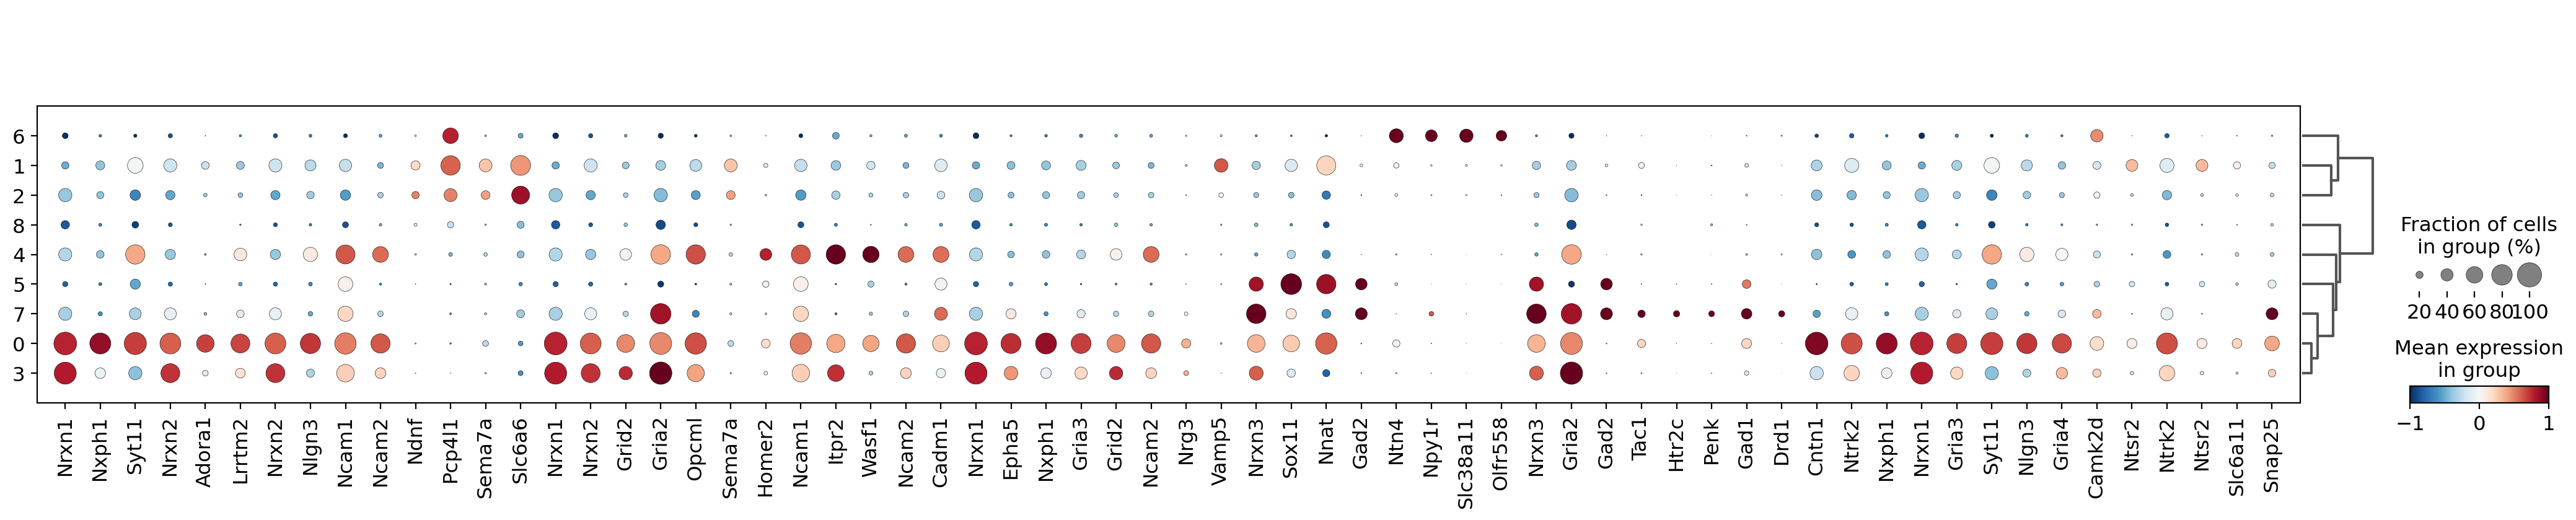

In [399]:
ax = sc.pl.dotplot(
    adata_neuron,
    new_markers,
    groupby=['leiden_neuron'],
    # swap_axes=True,
    dendrogram=True,
    # colorbar_title='mean z-score',
    # show_gene_labels=True,
    layer='scaled',
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'neuron_new_markers'
    # return_fig=True
)
# ax.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()
# !mv -v figures/dotplot_neuron_new_markers.pdf celltyping/neuron_new_markers_dotplot_v3.pdf
# !mv -v figures/heatmapneuron_new_markers.pdf celltyping/neuron_new_markers_heatmap_v3.pdf


### rank_genes_groups_dotplot

In [360]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_neuron, 
#     groupby=['leiden_neuron'],
#     swap_axes=True,
#     n_genes=5,
#     layer='scaled',
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     vmin=-4, vmax=4, cmap='RdBu_r',
# )

In [361]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_neuron, 
#     groupby=['leiden_neuron'],
#     n_genes=10,
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     groups=['3','4'],
#     vmin=-4, vmax=4, cmap='RdBu_r',
# )

# 

In [61]:
!date

Fri Nov 11 15:31:33 PST 2022
